# 03 — Signatures · Griffiths et al. 2021 (Breast Cancer)

Score the three embryonic modules on malignant cells and read their **geography** and pseudotime gradients
to decide **Gate 2** — does the module pattern appear? The **non-branching case** (organised Gast↔pSom
cross-repression along one axis + a terminal Crest gradient; §1) **passes (GO)**, with no bifurcation for
Gate 3 (NA). Deliverable signature UMAPs show **raw** scores (binding: raw in deliverables; smoothing aids
analysis only).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| module scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
for src, l in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{l}: {g.size}/{feat[src].size} genes present')

cells: 109353 | module scores present: ['Gast', 'pSom', 'Crest']
Gast: 80/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


### Module geography, pseudotime gradients, and the Gate-2 call

In [3]:
print('GLOBAL module means (define the Linear-pSom/Crest geometry class):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('\nsmoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('\ngradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'\nNeural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('Gate 2: organised Gast<->pSom cross-repression axis + terminal Crest gradient -> GO (non-branching)')
print('Gate 2 FLAG: Crest enriches the Gast-leaning terminus (inversion) -> pass anyway')
print('Gate 3: no bifurcation (all tips signature-identical, no Gast/pSom hub) -> NA')

GLOBAL module means (define the Linear-pSom/Crest geometry class): {'Gast': -0.0193, 'pSom': -0.0529, 'Crest': 0.0228}

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.31
  Crest_sm vs Gast_sm: r = -0.26
  Crest_sm vs pSom_sm: r = -0.76

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.402
  pSom_sm: rho = -0.364
  Crest_sm: rho = +0.290

Neural-crest-high decile mean pseudotime = 0.66 (terminal if ~1)
Gate 2: organised Gast<->pSom cross-repression axis + terminal Crest gradient -> GO (non-branching)
Gate 2 FLAG: Crest enriches the Gast-leaning terminus (inversion) -> pass anyway
Gate 3: no bifurcation (all tips signature-identical, no Gast/pSom hub) -> NA


### Signature UMAPs (raw scores) + colorbars

House linear layout (`X_umap_lin`, pseudotime left→right). One `(3.5,1.5)` panel per module with an external
colorbar, matching the reference deliverable style.

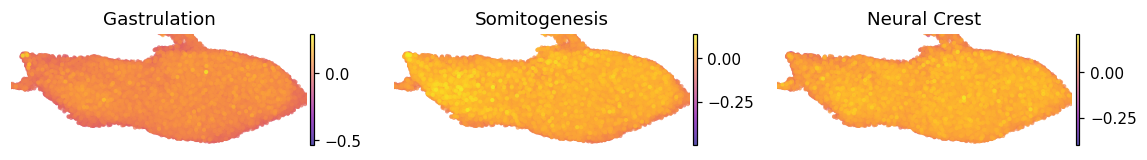

In [4]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5, 1.6))
for ax, (m, title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
fig.tight_layout(); plt.show()

<cell>:12: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell>:12: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell>:12: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


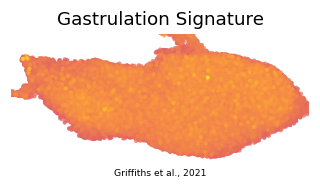

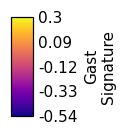

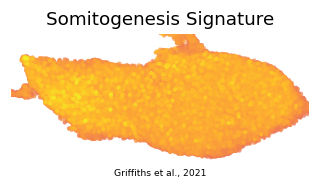

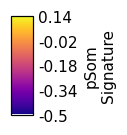

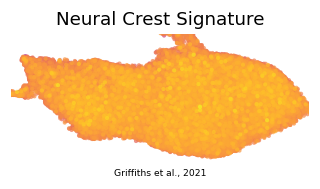

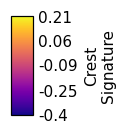

In [5]:
titles = {'Gast':'Gastrulation Signature', 'pSom':'Somitogenesis Signature', 'Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5, 1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66, 1)); cax = fcb.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf + colorbar')
plt.show()

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (109353, 21250)
